**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Tutorial 4, notebook 1

| | |
|---|---|
| **Goal** | Build the **present score** of the main firms of a sector (PW, Step 3 of the deck): four indicators from PATSTAT, each with its refinements, combined into one ranking and tested for robustness. |
| **Before this** | Tutorial 3 (notebook 30, citations), the lecture on patent valuation |
| **Time** | 90 min |
| **PATSTAT environment** | PROD |

← [Tutorial 3 · 31 Measuring knowledge spillovers](../tutorial_3/31_knowledge_spillovers.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md)

# Scoring the present value of firms

In the PW your investment bank asks: **which firms of the sector hold the most valuable patents today?** In Step 3 of the deck you answer with a **present score**: one number per firm, which ranks the firms of your sector.

**Present** means: based on what has **already happened** to the patents (citations received, decisions of the examiners, countries where they are protected).

## Where the four dimensions come from

Counting patents is not enough: a firm can file many cheap, narrow patents. Since 2011 **Clarivate** (the owner of the Derwent patent database) publishes every year the *Top 100 Global Innovators*, a ranking of the most innovative organizations in the world built on **four criteria**. The report is availble in **Materials** section of the moodle. The PW uses the same four, measured with PATSTAT inside one sector.

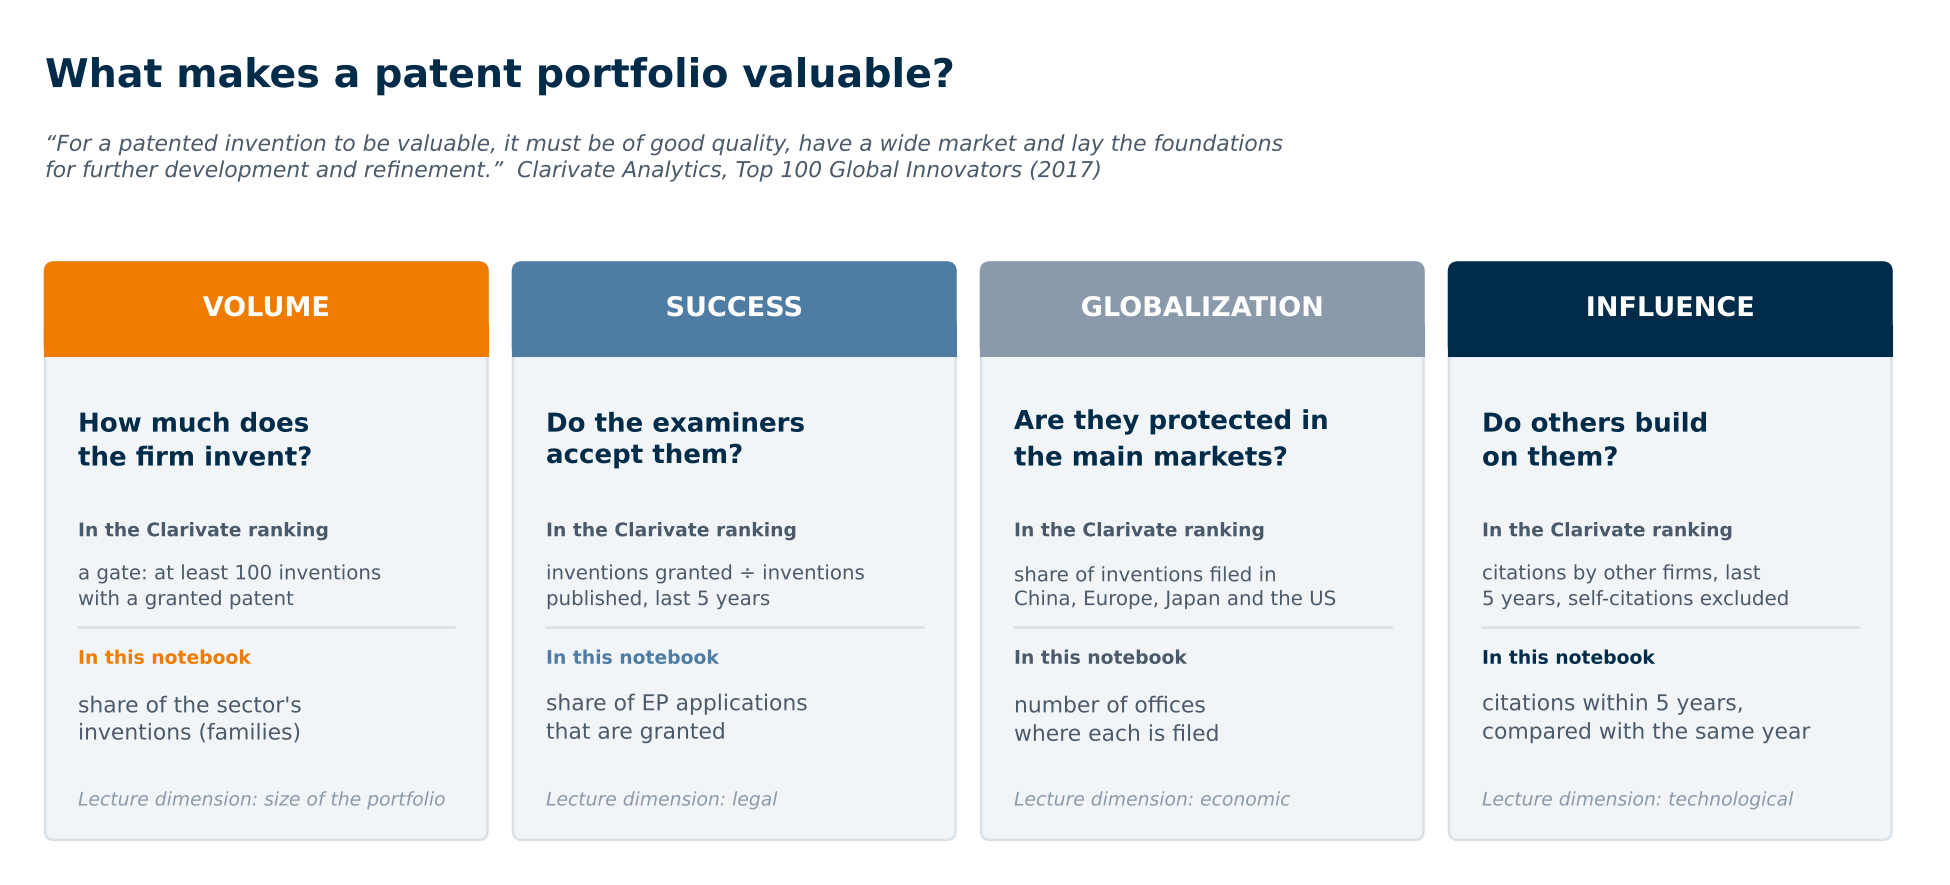

> *"It's not how much you patent, it's how good the innovation is."* (Clarivate, 2017)

| Dimension | The question | In the Clarivate ranking | In this notebook (basics) | Lecture |
|---|---|---|---|---|
| **Volume** | How much does the firm invent? | a **gate**: only organizations with at least 100 inventions with a granted patent in 5 years are ranked | share of the sector's families; the gate is `MIN_FAMILIES` | size |
| **Success** | Do the examiners accept its inventions? | inventions with a granted patent ÷ inventions published as applications, last 5 years | granted ÷ filed EP applications | legal |
| **Globalization** | Are they protected in the main markets? | share of inventions with **quadrilateral** families: filed in China, Europe, Japan and the US | number of offices per family | economic |
| **Influence** | Do others build on them? | citations from other organizations, last 5 years, **self-citations excluded** | citations within 5 years ÷ mean of the same priority year | technological |

Two differences from Clarivate matter for the PW. Clarivate ranks **whole organizations across all technologies**; we rank the firms of **one sector**, so every indicator is relative to that sector. And Clarivate's data and weights are not public: we build everything ourselves and must say how.

## How the notebook works

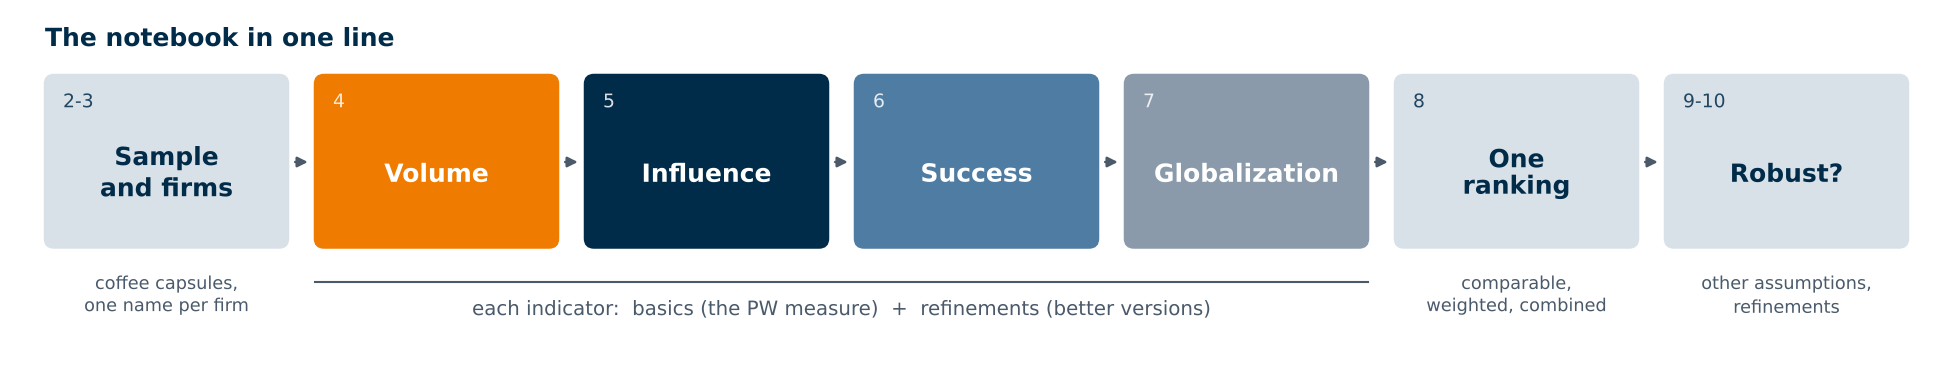

Sections 4 to 7 take one dimension at a time, always in two parts:

- **Basics**: the measure of the PW, the one that goes into the score;
- **Refinements**: better or richer versions of the same idea, some of them closer to Clarivate. You do not need them all: pick the ones that fit your sector and say why.

Section 8 then combines the four basic indicators into **one ranking**, section 9 checks that the ranking is robust, and section 10 shows how to bring a refinement into the score.

Everything you choose here (window, firms, weights) is a **design decision** of your algorithm: write it down, you will justify it in the technical appendix of the deck.

## 1. Setup

All imports in one cell. Besides the tables of the previous tutorials, we use `TLS228` (citations between families), `TLS215` (citation categories) and `TLS231` (legal events).

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sqlalchemy import func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,                 # applications: families, dates, grant
    TLS206_PERSON,                # persons: harmonised names and sector
    TLS207_PERS_APPLN,            # person <-> application links (who is applicant)
    TLS211_PAT_PUBLN,             # publications
    TLS212_CITATION,              # citations between publications, with their origin
    TLS215_CITN_CATEG,            # category of each citation (X, Y, A, I...)
    TLS224_APPLN_CPC,             # CPC classification: defines the sector
    TLS228_DOCDB_FAM_CITN,        # citations between DOCDB families
    TLS231_INPADOC_LEGAL_EVENT,   # legal events: refusals, fees paid in each state
)

ENV = "PROD"
patstat = PatstatClient(env=ENV)
db = patstat.orm()

OUT = Path("outputs")        # the score is saved here for the Magic Quadrant
OUT.mkdir(exist_ok=True)

NAVY, ORANGE, BLUE, GREY, MID, LIGHT = "#002B49", "#EF7B00", "#4F7CA3", "#4A5A6A", "#8A9AAB", "#D9E1E8"
LINES = [NAVY, ORANGE, BLUE, "#7A9A3A", "#A23B72", MID]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})
pd.set_option("display.max_colwidth", 45)

## 2. The sample: coffee capsules, by DOCDB family

The same sector as Tutorial 3: EP applications with a CPC code in **`B65D 85/804`** (coffee capsules and pods). As in Tutorial 1, we remove the blanks from `cpc_class_symbol` before matching.

- **Unit: the DOCDB family.** One invention is one family, whatever the number of applications it has (EP, divisional applications, US, CN...).
- **Time: the priority year** (`earliest_filing_year`, the date closest to the invention). We read 2000-2023: the whole period serves to follow the shares over time (section 4) and to choose the window.

In [2]:
CPC_PREFIX = "B65D85/804"    # coffee capsules and pods; change it to your PW sector :)

symbol = func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "")
q = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.earliest_filing_year,     # priority year of the family
        TLS201_APPLN.earliest_publn_year,      # first publication of the family
        TLS201_APPLN.granted,
        symbol.label("cpc"),
    )
    .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    .filter(symbol.like(CPC_PREFIX + "%"))
    .filter(TLS201_APPLN.appln_auth == "EP")
    .filter(TLS201_APPLN.earliest_filing_year.between(2000, 2023))
)
ep_all = patstat.df(q).sort_values("cpc").drop_duplicates("appln_id")   # one row per application
ep_all["cpc4"] = ep_all.cpc.str[:4]                                       # field: CPC subclass, e.g. B65D

families_all = (
    ep_all.groupby("docdb_family_id")
          .agg(priority_year=("earliest_filing_year", "min"),
               first_publn_year=("earliest_publn_year", "min"),
               cpc4=("cpc4", lambda s: s.mode().iat[0]))
          .reset_index()
)
families_all.loc[families_all.first_publn_year >= 9999, "first_publn_year"] = np.nan   # 9999 = unknown
print(f"{len(ep_all):,} EP applications in {len(families_all):,} families, priority years 2000-2023")

1,528 EP applications in 1,204 families, priority years 2000-2023


### 2.1 The time window

Two indicators need **time**: the EPO takes 4-5 years to decide on an application, and citations arrive over several years. Recent applications are not granted *yet*, and recent families are not cited *yet*: they would look weak only because they are young. The chart shows the share of EP applications granted today, by priority year. Where the curve drops, the applications are not worse, just younger.

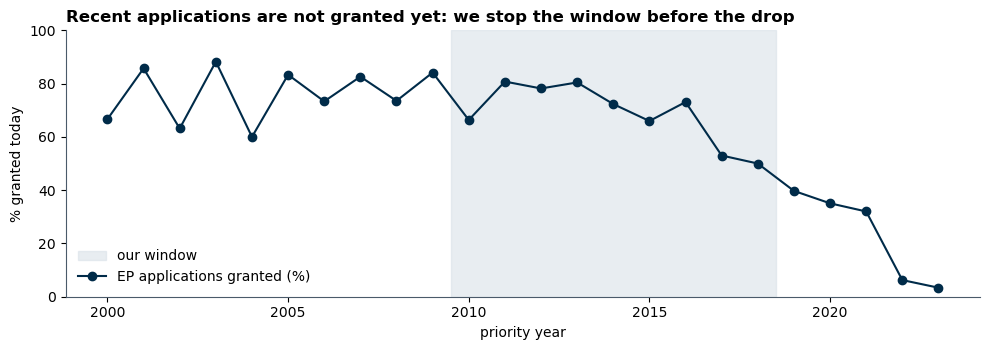

Window 2010-2018: 708 families, 890 EP applications


In [3]:
WINDOW = (2010, 2018)       # the priority years we score: see the shaded area

grant_rate = ep_all.groupby("earliest_filing_year").granted.apply(lambda s: (s == "Y").mean())
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.6, label="our window")
ax.plot(grant_rate.index, grant_rate * 100, marker="o", color=NAVY, label="EP applications granted (%)")
ax.set_ylim(0, 100)
ax.set_xlabel("priority year")
ax.set_ylabel("% granted today")
ax.legend(frameon=False, loc="lower left")
ax.set_title("Recent applications are not granted yet: we stop the window before the drop")
plt.tight_layout()
plt.show()

ep = ep_all[ep_all.earliest_filing_year.between(*WINDOW)].copy()
families = families_all[families_all.priority_year.between(*WINDOW)].copy()
FAMILIES = [int(f) for f in families.docdb_family_id]
print(f"Window {WINDOW[0]}-{WINDOW[1]}: {len(FAMILIES):,} families, {len(ep):,} EP applications")

## 3. The firms: who owns which family?

The owners are the **applicants** of the EP applications (`applt_seq_nr > 0` in `TLS207`), with their harmonised name `psn_name` and their sector `psn_sector` from `TLS206`. A family filed by two firms together counts for **both** of them (*full counting*). We read the owners of the whole period, 2000-2023.

In [4]:
SAMPLE_ALL = [int(i) for i in ep_all.appln_id]
q = (
    db.query(TLS207_PERS_APPLN.appln_id, TLS206_PERSON.psn_name, TLS206_PERSON.psn_sector)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)
    .filter(TLS207_PERS_APPLN.appln_id.in_(SAMPLE_ALL))
)
owners = patstat.df(q)
owners["psn_name"] = owners.psn_name.str.strip()
owners["docdb_family_id"] = owners.appln_id.map(ep_all.set_index("appln_id").docdb_family_id)
owners.psn_sector.value_counts(dropna=False)

psn_sector
COMPANY           1326
UNKNOWN            149
INDIVIDUAL         104
                     2
UNIVERSITY           2
GOV NON-PROFIT       1
Name: count, dtype: int64

### 3.1 One firm, one name

`psn_name` may merge spelling variants of the same name, but **not different legal entities of the same group**. In our sector the most important case is Nestlé: for years it filed its patents as **NESTEC SA**, its technical subsidiary, which was merged into **SOCIETE DES PRODUITS NESTLE SA** in 2018. If we do not merge them, Nestlé is split in two, both halves look smaller than they are, and the share of "Nestlé" seems to jump in 2018 only because the name changed.

We merge names with **patterns**, so that every variant is caught (NESTEC SA, NESTEC S.A., NESTLE SA...). The same holds for the Senseo pads of Douwe Egberts: filed by Sara Lee/DE, then D.E Master Blenders, now Jacobs Douwe Egberts. The cell prints every name that has been merged: **check the list**, a pattern can catch a name it should not.

In [5]:
GROUPS = {
    "NESTLE": r"NESTEC|NESTLE",                         # Nestec SA merged into Nestle in 2018
    "JDE (DOUWE EGBERTS)": r"DOUWE EGBERTS|SARA LEE",   # Sara Lee/DE -> D.E Master Blenders -> JDE
    # "GROUP": r"PATTERN1|PATTERN2",                    <- add the groups of your sector
}


def firm_name(psn_name):
    """The group a name belongs to, or the name itself."""
    for group, pattern in GROUPS.items():
        if re.search(pattern, psn_name):
            return group
    return psn_name


owners["firm"] = owners.psn_name.map(firm_name)
merged = owners[owners.firm != owners.psn_name]
print("Names merged into a group:")
display(merged.groupby(["firm", "psn_name"]).docdb_family_id.nunique().rename("families").to_frame())

companies = owners[owners.psn_sector.fillna("").str.contains("COMPANY")]
fam_firm_all = companies[["docdb_family_id", "firm"]].drop_duplicates()        # one row per (family, firm)
fam_firm = fam_firm_all[fam_firm_all.docdb_family_id.isin(FAMILIES)]          # the window only
print(f"In the window: {fam_firm.firm.nunique():,} companies own {fam_firm.docdb_family_id.nunique():,} "
      f"of the {len(FAMILIES):,} families")

Names merged into a group:


families
firm                psn_name                           
JDE (DOUWE EGBERTS) KONINKLIJKE DOUWE EGBERTS        79
                    SARA LEE/DE                       4
NESTLE              NESTEC                          110

In the window: 194 companies own 639 of the 708 families


### 3.2 Which firms do we score?

We score the firms with the most families in the window. Two parameters, both design choices:

- `N_FIRMS`: how many firms you want to retain;
- `MIN_FAMILIES`: a minimum portfolio. With 3 families, one citation or one refusal changes a rate completely: the indicator is noise. This is the same idea as the Clarivate **volume gate** (at least 100 inventions), scaled to one sector.

In [6]:
N_FIRMS = 10
MIN_FAMILIES = 10

n_families = fam_firm.groupby("firm").docdb_family_id.nunique().sort_values(ascending=False)
TOP = list(n_families[n_families >= MIN_FAMILIES].head(N_FIRMS).index)
SHORT = {f: f.title()[:28] for f in TOP}     # short names for the charts

print(f"We score {len(TOP)} firms")
n_families.loc[TOP].rename("families").to_frame()

We score 10 firms


,families
firm,
NESTLE,136
JDE (DOUWE EGBERTS),58
K-FEE SYSTEM,21
DELICA,19
LUIGI LAVAZZA,19
SARONG,14
KRAFT FOODS R & D,12
TUTTOESPRESSO,11
CAFFITALY SYSTEM,11


In [7]:
def firm_bars(values, title, xlabel, fmt="{:.2f}", ref=None, ref_label=None, color=NAVY):
    """One horizontal bar per scored firm, in the order of TOP (largest portfolio on top)."""
    v = values.reindex(TOP)[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(v) + 1.2))
    ax.barh([SHORT[f] for f in v.index], v.values, color=color)
    for y, x in enumerate(v.values):
        if pd.notna(x):
            ax.text(x, y, (" " + fmt.format(x)) if x >= 0 else (fmt.format(x) + " "), va="center",
                    ha="left" if x >= 0 else "right", fontsize=9, color=GREY)
    if ref is not None:
        ax.axvline(ref, color=ORANGE, ls="--", lw=1.2)
        ax.text(ref, len(v) - 0.45, f" {ref_label}", color=ORANGE, fontsize=9, va="bottom")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def per_firm(column, how="mean"):
    """Aggregate a column of `families` over the families of each scored firm."""
    table = fam_firm.merge(families[["docdb_family_id", column]], on="docdb_family_id")
    return table.groupby("firm")[column].agg(how).reindex(TOP).rename(column)

## 4. Volume: weight in the sector

### 4.1 Basics: share of the sector's families

$$\text{Volume}_f=\frac{\text{families of firm } f}{\text{all families of the sector in the window}}$$

The denominator is **all** the families of the window, including those of individuals, universities and small firms: volume is a share of the whole sector.

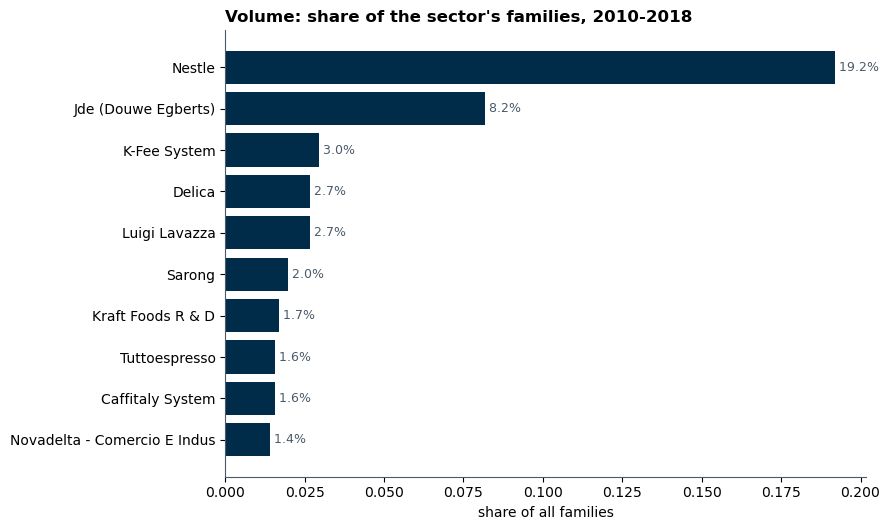

In [8]:
volume = (n_families / len(FAMILIES)).reindex(TOP).rename("volume")
firm_bars(volume, "Volume: share of the sector's families, 2010-2018", "share of all families", fmt="{:.1%}")

**Thinking about..** Volume measures size, not quality: a firm can file many cheap, narrow patents.

### 4.2 Refinement: shares over time, who gains and who loses?

One number for nine years hides the dynamics. The same share, **year by year**, shows changes of power in the sector. Coffee capsules have a famous turning point: the main Nespresso patents expired around **2012**, and many firms entered with compatible capsules.

$$\text{Share}_{f,t}=\frac{\text{families of firm } f \text{ with priority year } t}{\text{all families of the sector with priority year } t}$$

We plot it over the whole period, smoothed with a 3-year moving average (one year is often a handful of families). The last two years are incomplete because applications are published 18 months after filing; a share suffers less than a count, but read them with care.

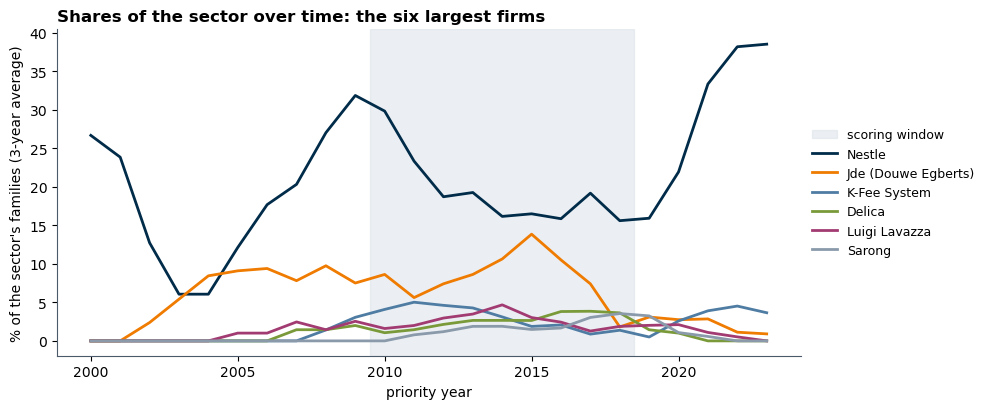

In [9]:
yearly = (fam_firm_all.merge(families_all[["docdb_family_id", "priority_year"]], on="docdb_family_id")
                     .groupby(["priority_year", "firm"]).docdb_family_id.nunique()
                     .unstack(fill_value=0))
total = families_all.groupby("priority_year").docdb_family_id.nunique()
share = yearly.reindex(columns=TOP, fill_value=0).div(total, axis=0)
smooth = share.rolling(3, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(WINDOW[0] - 0.5, WINDOW[1] + 0.5, color=LIGHT, alpha=0.5, label="scoring window")
for k, f in enumerate(TOP[:6]):
    ax.plot(smooth.index, smooth[f] * 100, color=LINES[k], lw=2, label=SHORT[f])
ax.set_xlabel("priority year")
ax.set_ylabel("% of the sector's families (3-year average)")
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.set_title("Shares of the sector over time: the six largest firms")
plt.tight_layout()
plt.show()

To turn the dynamics into a number, the **change of share** inside the window: the average share in the second half (2015-2018) minus the average share in the first half (2010-2014), in percentage points. Positive means the firm is gaining weight.

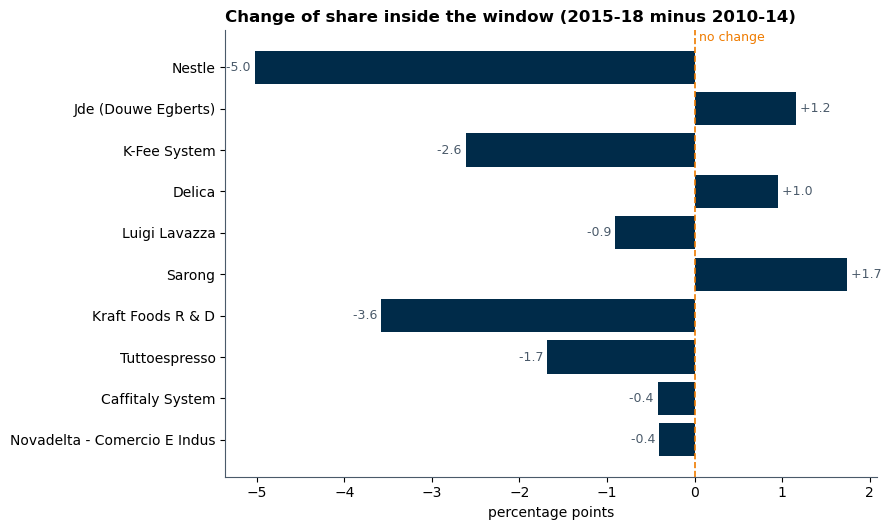

In [10]:
MID_YEAR = 2014
in_window = share.loc[WINDOW[0]:WINDOW[1]]
volume_change = ((in_window.loc[MID_YEAR + 1:].mean() - in_window.loc[:MID_YEAR].mean()) * 100).rename("volume_change")
firm_bars(volume_change, "Change of share inside the window (2015-18 minus 2010-14)", "percentage points",
          fmt="{:+.1f}", ref=0, ref_label="no change")

## 5. Influence: technological impact

### 5.1 Basics: forward citations within 5 years, compared with the same year

A family is influential if later inventions **build on it**, so we count its forward citations, as in the lecture:

- **between families**: `TLS228_DOCDB_FAM_CITN` has one row per pair *citing family → cited family*, collecting the citations made by any publication of one family to any publication of the other;
- **within 5 years** of the first publication of the cited family, so that old and young families have the same time to be cited. The date of a citation is the first publication year of the **citing** family;
- we drop a family citing itself; citations from the same firm (self-citations) stay in, as in the OECD indicators.

First, the citations and their dates:

In [11]:
q = db.query(
    TLS228_DOCDB_FAM_CITN.docdb_family_id.label("citing_family"),
    TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.label("cited_family"),
).filter(TLS228_DOCDB_FAM_CITN.cited_docdb_family_id.in_(FAMILIES))
fcit = patstat.df(q)
fcit = fcit[fcit.citing_family != fcit.cited_family]

q = (
    db.query(TLS201_APPLN.docdb_family_id, func.min(TLS201_APPLN.earliest_publn_year).label("year"))
    .filter(TLS201_APPLN.docdb_family_id.in_([int(f) for f in fcit.citing_family.unique()]))
    .filter(TLS201_APPLN.earliest_publn_year < 9999)
    .group_by(TLS201_APPLN.docdb_family_id)
)
fcit["citing_year"] = fcit.citing_family.map(patstat.df(q).set_index("docdb_family_id").year)
fcit["cited_year"] = fcit.cited_family.map(families.set_index("docdb_family_id").first_publn_year)
fcit["lag"] = fcit.citing_year - fcit.cited_year          # years between the two first publications
print(f"{len(fcit):,} citing-cited pairs, from {fcit.citing_family.nunique():,} citing families")

14,082 citing-cited pairs, from 4,517 citing families


A raw count is unfair across years (lecture, *Comparing forward citations fairly*): older families had more citing patents around them and more time in the data. So we divide each family's count by the **mean of the families with the same priority year** $t$.

What about the **field**? Citation habits differ a lot between fields, so in general the comparison should be made within the same field and year. Here all families belong to the same CPC group (`B65D 85/804`): the field is already fixed by the sample, and comparing within the year **is** comparing within field and year.

$$\text{fwd}^{norm}_{i}=\frac{\text{fwd}_{i}}{\bar F_{t}}\qquad\text{with}\qquad \bar F_{t}=\frac{1}{N_{t}}\sum_{j\,\in\,t}\text{fwd}_{j}$$

- $\text{fwd}_i$: citations received by family $i$ within 5 years; $t$ is its priority year;
- $N_{t}$: the number of families of the sector with priority year $t$.

A value of **1** means "cited as much as the average family of the sector filed in the same year"; 2 means twice as much.

We write it as a function of the window `w`, because the refinements use other windows. A window is counted only if the data cover it: PATSTAT Spring 2026 has the citations up to about 2025 (`LAST_YEAR`), so a family first published in 2022 has no complete 5-year window, and its value is set to *missing* rather than to a count that is too low.

In [12]:
LAST_YEAR = 2025                      # last year of citations covered by the PATSTAT edition
COHORT = ["priority_year"]            # one CPC group: the field is fixed, we compare within the year


def forward_citations(w):
    """Citations received within w years of the first publication; missing if the window is not complete."""
    counts = fcit[fcit.lag.between(0, w)].groupby("cited_family").citing_family.nunique()
    fwd = families.docdb_family_id.map(counts).fillna(0)
    complete = families.first_publn_year + w <= LAST_YEAR
    return fwd.where(complete)


def normalise_by_cohort(values):
    """Each family's value divided by the mean of the families with the same priority year."""
    mean_cohort = values.groupby([families[c] for c in COHORT]).transform("mean")
    return (values / mean_cohort).where(mean_cohort > 0, 0.0).where(values.notna())


families["fwd5"] = forward_citations(5)
families["fwd5_norm"] = normalise_by_cohort(families.fwd5)
families.groupby("priority_year").fwd5.mean().round(2).to_frame("mean fwd5 (the denominator)").T

priority_year,2010,2011,2012,2013,2014,2015,2016,2017,2018
mean fwd5 (the denominator),26.64,17.95,16.86,13.51,12.05,9.98,10.26,5.28,4.75


Read the means by year: they move from year to year, and they fall in the last years because younger families are cited less or the data stop. The normalisation removes this, because each family is compared only with the families of its own year. The influence of a firm is the **average** of its families:

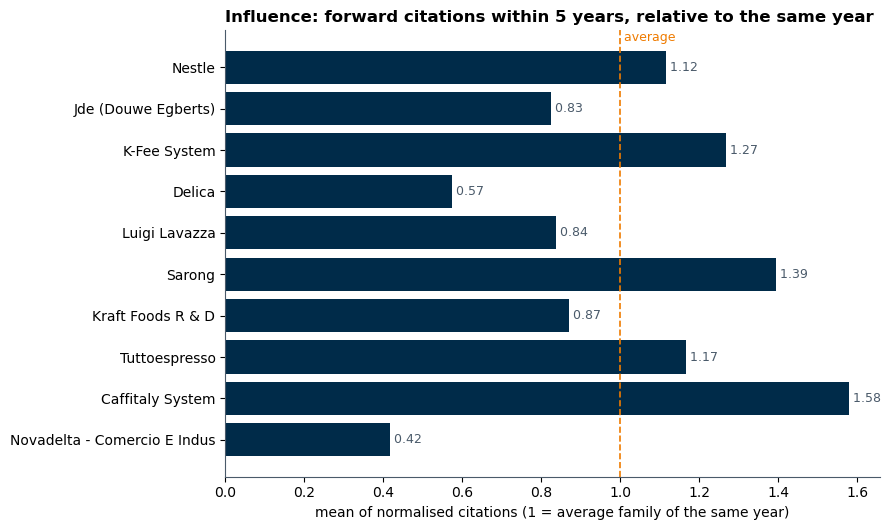

In [13]:
influence = per_firm("fwd5_norm").rename("influence")
firm_bars(influence, "Influence: forward citations within 5 years, relative to the same year",
          "mean of normalised citations (1 = average family of the same year)", ref=1, ref_label="average")

**Watch out.** An average is pulled up by one star family: a firm with 9 uncited families and one blockbuster can look influential. Refinement 5.4 looks at the top of the distribution instead.

### 5.2 Refinement: a shorter or a longer window (3 and 7 years)

A short window measures how fast a family is noticed; a long one is closer to its total impact, but the last priority years have no complete window yet, so it rests on the older families only. Does the window change the story?

In [14]:
for w in [3, 7]:
    families[f"fwd{w}_norm"] = normalise_by_cohort(forward_citations(w))

by_window = pd.concat([per_firm(f"fwd{w}_norm") for w in [3, 5, 7]], axis=1)
by_window.columns = ["3 years", "5 years", "7 years"]
print("Families with a complete window:",
      {w: f"{families[f'fwd{w}_norm'].notna().mean():.0%}" for w in [3, 5, 7]})
print("Rank correlation with the 5-year ranking:",
      by_window.corr(method="spearman")["5 years"].drop("5 years").round(2).to_dict())
by_window.rename(index=SHORT).round(2)

Families with a complete window: {3: '100%', 5: '92%', 7: '71%'}
Rank correlation with the 5-year ranking: {'3 years': 0.88, '7 years': 0.94}


,3 years,5 years,7 years
firm,,,
Nestle,1.07,1.12,1.18
Jde (Douwe Egberts),0.90,0.83,0.92
K-Fee System,1.34,1.27,1.27
Delica,0.48,0.57,0.62
Luigi Lavazza,0.84,0.84,0.85
Sarong,1.02,1.39,1.61
Kraft Foods R & D,0.82,0.87,0.83
Tuttoespresso,1.25,1.17,1.19
Caffitaly System,1.51,1.58,1.33


If the order of the firms is the same in the three columns, the choice of the window does not matter much. A firm that climbs with the longer window has patents noticed late but used for long.

### 5.3 Refinement: who cites the firm, competitors or examiners?

A citation can be added by the **applicant** of the citing patent (origin `APP` in `TLS212`) or by the **examiner** during the search or examination (`SEA`, `ISR`, `SUP`, `EXA`...). The difference matters (lecture on knowledge spillovers):

- an **applicant** citation means that a competitor *knew* the patent when it filed: a real knowledge flow, and visibility in the market;
- an **examiner** citation means that the patent is relevant prior art, which the citing applicant may never have read.

The origin is recorded at the level of **publications**, so we go from our families to their publications (`TLS211`), then to the publications that cite them. We keep only citing **EP** publications: at the USPTO applicants must disclose all the prior art they know, so US applicant citations would mix two different practices (Tutorial 3).

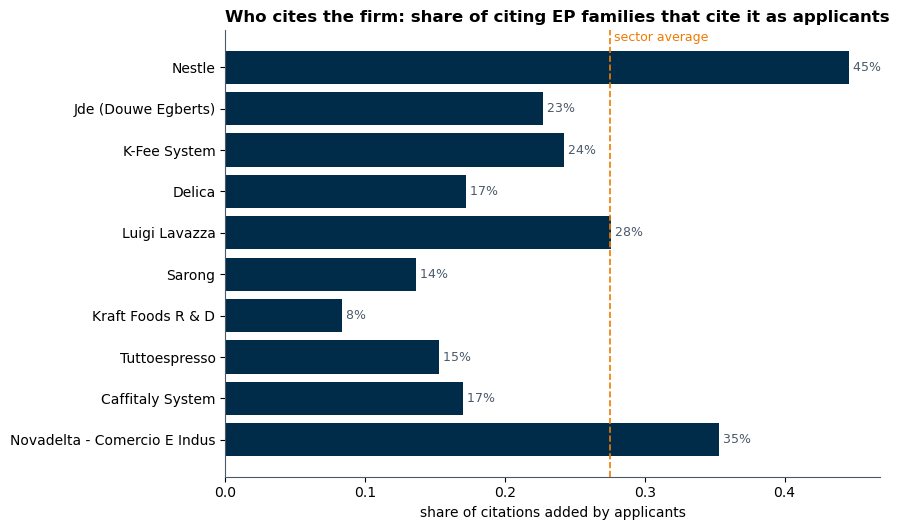

In [15]:
CITING_OFFICES = ["EP"]

# 1. All the publications of the families of the window (any office)
q = (db.query(TLS211_PAT_PUBLN.pat_publn_id, TLS201_APPLN.docdb_family_id.label("cited_family"))
     .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
     .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES)))
pubs = patstat.df(q)

# 2. The citations they receive, with their origin
q = (
    db.query(TLS212_CITATION.pat_publn_id.label("citing_publn"), TLS212_CITATION.citn_replenished,
             TLS212_CITATION.citn_id, TLS212_CITATION.citn_origin, TLS212_CITATION.cited_pat_publn_id)
    .filter(TLS212_CITATION.cited_pat_publn_id.in_([int(p) for p in pubs.pat_publn_id]))
)
cit = patstat.df(q)
cit["cited_family"] = cit.cited_pat_publn_id.map(pubs.set_index("pat_publn_id").cited_family)

# 3. The office and the family of each citing publication
q = (
    db.query(TLS211_PAT_PUBLN.pat_publn_id.label("citing_publn"), TLS211_PAT_PUBLN.publn_auth.label("citing_office"),
             TLS201_APPLN.docdb_family_id.label("citing_family"))
    .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS211_PAT_PUBLN.pat_publn_id.in_([int(p) for p in cit.citing_publn.unique()]))
)
cit = cit.merge(patstat.df(q), on="citing_publn")
cit = cit[cit.citing_family != cit.cited_family]
cit["who"] = np.where(cit.citn_origin.str.strip() == "APP", "applicant", "examiner or other")

ep_cit = (cit[cit.citing_office.isin(CITING_OFFICES)]
          .drop_duplicates(["citing_family", "cited_family", "who"])
          .merge(fam_firm, left_on="cited_family", right_on="docdb_family_id"))
applicant_share = (ep_cit.who == "applicant").groupby(ep_cit.firm).mean().reindex(TOP).rename("applicant_share")
firm_bars(applicant_share, "Who cites the firm: share of citing EP families that cite it as applicants",
          "share of citations added by applicants", fmt="{:.0%}",
          ref=(ep_cit.who == "applicant").mean(), ref_label="sector average")

A firm with a high applicant share is **watched by its competitors**: its patents are known reference points. Read it with the number of citations: 50% of 4 citations says little.

### 5.4 Refinement: blocking patents, X and I citations at the top of the sector

Not all citations are equal. In a search report the examiner gives each cited document a **category** (`TLS215_CITN_CATEG`):

| Category | Meaning for the citing application |
|---|---|
| **X** | the cited document **alone** destroys the novelty or the inventive step of the claim |
| **I** | the cited document **alone** destroys the inventive step of the claim (EPO, since 2012) |
| Y | relevant only in combination with another document |
| A | general background |

A family often cited as **X or I** stood in the way of later applications: competitors had to narrow their claims or give up. It is a **blocking patent**, the strongest form of influence. `CITN_CATEG` can hold several letters (e.g. `XI`), so we look for an X or an I anywhere in it.

For each family we count the distinct families that cite it as X or I, and we call **blocking** the families in the **top 10% of their priority year**, with at least one such citation. As in 5.1, comparing inside the year is fair to young families, and the field is fixed by the sample.

Each family is then **blocking (1) or not (0)**. For a firm we compute two numbers from these 0/1 values:

$$\text{Blocking share}_f=\frac{\text{blocking families of } f}{\text{families of } f}\qquad\qquad \text{Share of the sector's blocking}_f=\frac{\text{blocking families of } f}{\text{all blocking families of the sector}}$$

The first is the average of the 0/1 values over the firm's families: the share of its portfolio that blocks others.

In [16]:
TOP_SHARE = 0.10              # top 10% of each priority year

q = (
    db.query(TLS215_CITN_CATEG.pat_publn_id.label("citing_publn"), TLS215_CITN_CATEG.citn_replenished,
             TLS215_CITN_CATEG.citn_id, TLS215_CITN_CATEG.citn_categ)
    .filter(TLS215_CITN_CATEG.pat_publn_id.in_([int(p) for p in cit.citing_publn.unique()]))
)
categ = patstat.df(q)
xi_keys = categ[categ.citn_categ.str.contains("X|I", regex=True)][["citing_publn", "citn_replenished", "citn_id"]]
xi = cit.merge(xi_keys.drop_duplicates(), on=["citing_publn", "citn_replenished", "citn_id"])

families["xi"] = families.docdb_family_id.map(xi.groupby("cited_family").citing_family.nunique()).fillna(0)
threshold = families.groupby(COHORT).xi.transform(lambda s: s.quantile(1 - TOP_SHARE))   # cut-off of each year
families["blocking"] = ((families.xi >= threshold) & (families.xi > 0)).astype(int)

owners_of = fam_firm.groupby("docdb_family_id").firm.agg(", ".join)     # co-owned families: all owners
print(f"Blocking families: {families.blocking.sum():,} of {len(families):,}. The ten strongest:")
(families.assign(owners=families.docdb_family_id.map(owners_of).fillna("(not a company)"))
         .sort_values("xi", ascending=False)[["docdb_family_id", "priority_year", "xi", "owners"]].head(10))

Blocking families: 99 of 708. The ten strongest:


,docdb_family_id,priority_year,xi,owners
605,54352460,2015,23.0,ADVANCED TECHNOLOGY ASSETS
488,50942711,2013,20.0,JDE (DOUWE EGBERTS)
288,45496540,2010,19.0,K-FEE SYSTEM
546,52432846,2013,18.0,BISERKON HOLDINGS
754,59684715,2016,17.0,ECOINNO
606,54360021,2015,16.0,PHILIP MORRIS PRODUCTS
400,48745944,2012,14.0,TUTTOESPRESSO
188,42357576,2010,13.0,NESTLE
346,47143911,2011,13.0,NESTLE
230,43743513,2010,13.0,NESTLE


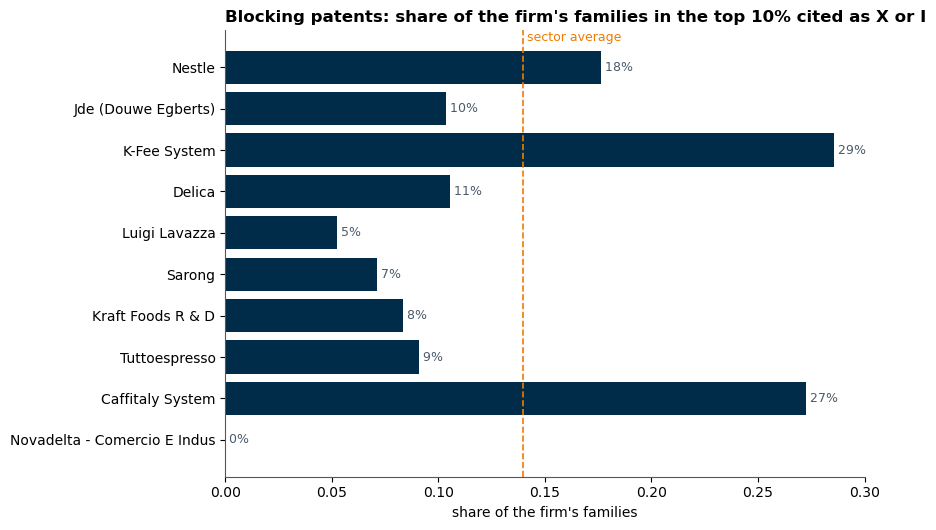

,blocking families,blocking_share,share_of_sector_blocking
firm,,,
Nestle,24,0.18,0.24
Jde (Douwe Egberts),6,0.10,0.06
K-Fee System,6,0.29,0.06
Delica,2,0.11,0.02
Luigi Lavazza,1,0.05,0.01
Sarong,1,0.07,0.01
Kraft Foods R & D,1,0.08,0.01
Tuttoespresso,1,0.09,0.01
Caffitaly System,3,0.27,0.03


In [17]:
blocking_share = per_firm("blocking").rename("blocking_share")                 # mean of 0/1 = share of families
blocking_power = (per_firm("blocking", "sum") / families.blocking.sum()).rename("share_of_sector_blocking")

firm_bars(blocking_share, f"Blocking patents: share of the firm's families in the top {TOP_SHARE:.0%} cited as X or I",
          "share of the firm's families", fmt="{:.0%}", ref=families.blocking.mean(), ref_label="sector average")
pd.concat([per_firm("blocking", "sum").rename("blocking families"), blocking_share, blocking_power],
          axis=1).rename(index=SHORT).round(2)

Two readings: `blocking_share` is the **quality** of the portfolio (how many of its families block others), `share_of_sector_blocking` is the **power** in the sector (how many of the sector's blocking patents the firm owns). A small firm can have a high share and little power; a large firm the opposite.

## 6. Success: quality as judged by the examiners

Success asks: **when the firm applies for a patent, do the examiners accept it?** A granted patent has passed an examination of novelty and inventive step, so a high grant rate signals inventions of good quality and well-drafted applications. We measure it in two ways, which answer two **different questions**. The example shows a firm with two inventions:

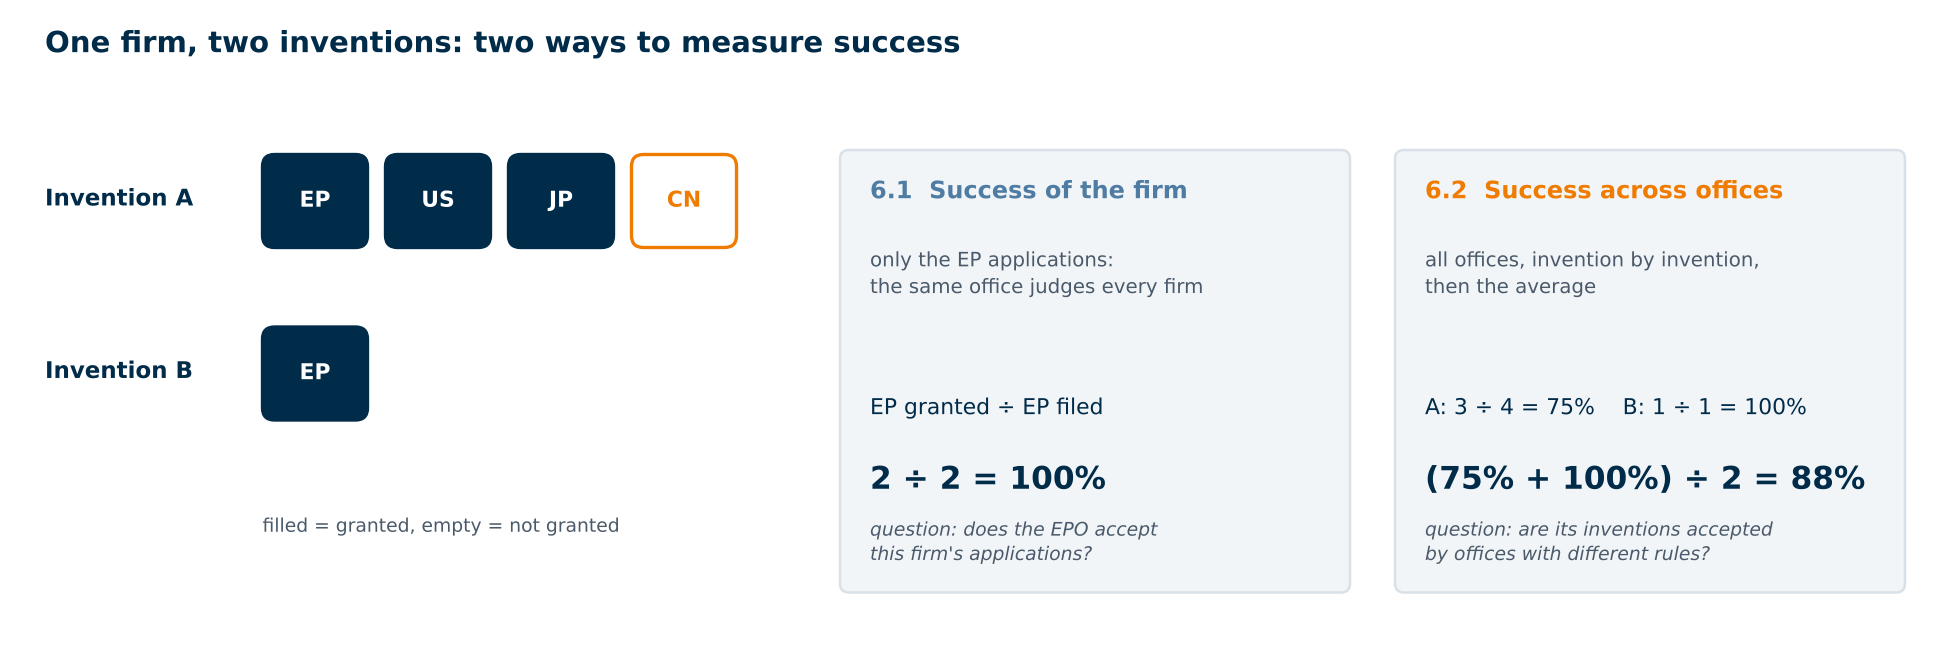

| | 6.1 Success of the firm (basics) | 6.2 Success across offices (refinement) |
|---|---|---|
| What we count | the firm's **EP applications** | the firm's **inventions** (families), with all their applications |
| Who judges | always the **EPO** | each office, with its own rules |
| The question | does the EPO accept this firm's applications? | are the firm's inventions accepted around the world? |
| Strength | the same judge for every firm: a fair comparison | rewards inventions that pass several different examinations |
| Limit | says nothing about the other markets | mixes offices with different standards, and depends on where the firm chooses to file |

Clarivate measures success at the level of inventions, like 6.2; we use 6.1 as the basic measure because one judge for all firms makes the comparison cleaner.

### 6.1 Basics: share of EP applications granted

$$\text{Success}_f=\frac{\text{granted EP applications of firm } f}{\text{EP applications of firm } f}$$

`granted` is `Y` when PATSTAT has an indication of a grant, `N` otherwise. `N` therefore mixes refused, withdrawn and still pending applications; with the window ending in 2018 most applications have been decided (section 2.1).

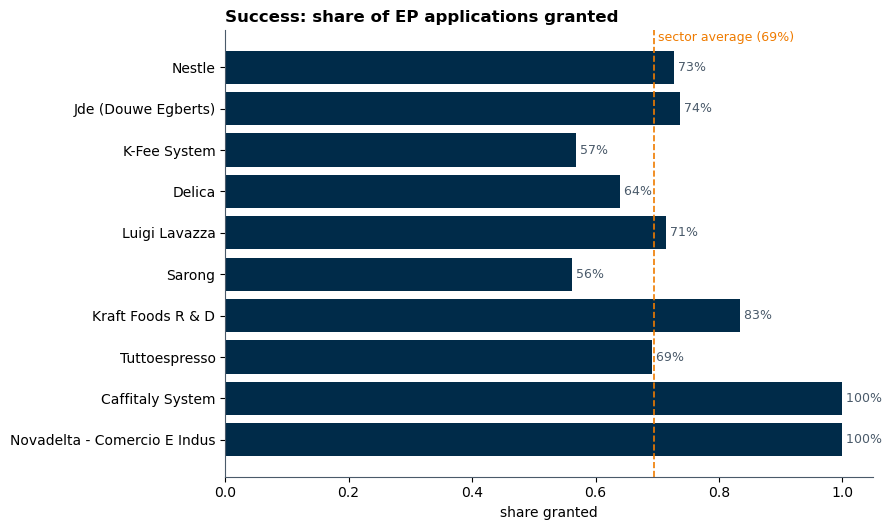

In [18]:
apps = ep[["appln_id", "docdb_family_id", "granted"]].merge(fam_firm, on="docdb_family_id")
success = apps.groupby("firm").granted.apply(lambda s: (s == "Y").mean()).reindex(TOP).rename("success")
sector_rate = (ep.granted == "Y").mean()

firm_bars(success, "Success: share of EP applications granted", "share granted", fmt="{:.0%}",
          ref=sector_rate, ref_label=f"sector average ({sector_rate:.0%})")


### 6.2 Refinement: success across offices, invention by invention

Offices apply different **patentability rules and standards**: the same invention can be granted in one country and refused in another. An invention granted at the EPO, in the USA, in China and in Japan has passed four different examinations: a strong signal. So we change the unit, from applications to **inventions**:

1. for each family, the share of its national applications that are granted: in the example, invention A gets 3 ÷ 4 = 75%, invention B 1 ÷ 1 = 100%;
2. for each firm, the average over its families: (75% + 100%) ÷ 2 = 88%.

Two kinds of family members are **not** national applications, and we leave them out:

- `WO`: a PCT application is a request, not protection in a country;
- applications of kind **`T`** (`appln_kind` in `TLS201`): some offices (Spain, Poland, Portugal, Denmark, Austria...) record the **translation of a granted EP patent** as a national application. It is the EP patent validated in that country, not a second examination: it is always "granted", and counting it would inflate both success and globalization.

Then, how different are the offices? The grant rate of the applications of our families, by office:

In [19]:
q = (
    db.query(TLS201_APPLN.appln_id, TLS201_APPLN.docdb_family_id, TLS201_APPLN.appln_auth,
             TLS201_APPLN.appln_kind, TLS201_APPLN.granted)
    .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
)
members = patstat.df(q).drop_duplicates("appln_id")

# national applications: no PCT requests (WO), no translations of EP patents (kind T)
national = members[(members.appln_auth != "WO") & (members.appln_kind != "T")]

office_rate = national.groupby("appln_auth").agg(applications=("appln_id", "size"),
                                                  granted=("granted", lambda s: (s == "Y").mean()))
office_rate[office_rate.applications >= 20].sort_values("granted", ascending=False).round(2).T

appln_auth,PL,RS,MY,ZA,NL,ES,PT,DK,RU,CN,...,PH,IT,HR,HK,CL,HU,IN,NZ,SG,SI
applications,225.0,29.0,43.0,115.0,41.0,439.0,179.00,155.00,270.00,543.00,...,87.0,108.00,49.00,72.00,75.0,90.0,25.0,33.0,128.0,33.0
granted,1.0,1.0,1.0,1.0,1.0,1.0,0.99,0.99,0.72,0.71,...,0.1,0.08,0.06,0.04,0.0,0.0,0.0,0.0,0.0,0.0


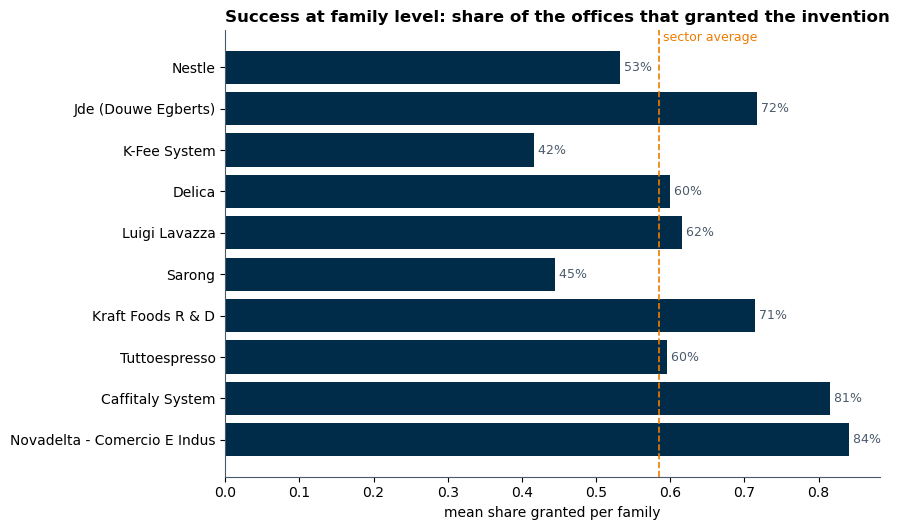

,6.1 firm (EP),6.2 across offices
firm,,
Nestle,0.73,0.53
Jde (Douwe Egberts),0.74,0.72
K-Fee System,0.57,0.42
Delica,0.64,0.60
Luigi Lavazza,0.71,0.62
Sarong,0.56,0.45
Kraft Foods R & D,0.83,0.71
Tuttoespresso,0.69,0.60
Caffitaly System,1.00,0.81


In [20]:
families["family_success"] = families.docdb_family_id.map(
    national.groupby("docdb_family_id").granted.apply(lambda s: (s == "Y").mean()))
family_success = per_firm("family_success")

firm_bars(family_success, "Success at family level: share of the offices that granted the invention",
          "mean share granted per family", fmt="{:.0%}", ref=families.family_success.mean(), ref_label="sector average")
pd.concat([success, family_success], axis=1).rename(columns={"success": "6.1 firm (EP)", "family_success": "6.2 across offices"}).rename(index=SHORT).round(2)

**Reading the two columns together**

- high in **both**: the firm's inventions are accepted by the EPO and elsewhere;
- high in 6.1, low in 6.2: its applications pass at the EPO but meet resistance in other offices (often where the firm files late or with broader claims);
- low in 6.1, high in 6.2: the EPO is stricter with this firm than the other offices are.


## 7. Globalization: breadth of market protection

### 7.1 Basics: offices per family

Protecting an invention in many countries is expensive, so firms do it only for inventions they expect to be worth it (lecture, *Family size*). For each family we count the distinct offices (`appln_auth`) of its applications, at any office:

- we use the national applications of 6.2: no `WO` (a PCT request is not protection) and no kind `T` (translations of EP patents: they are the EP patent validated in a country, and refinement 7.2 counts them properly);
- `EP` counts as one office here; refinement 7.2 opens it up into states.

$$\text{Globalization}_f=\text{mean number of distinct offices per family of firm } f$$

Most frequent offices in the families of the sector:
appln_auth
EP    890
US    795
CN    543
JP    456
ES    439
CA    417
AU    390
BR    334


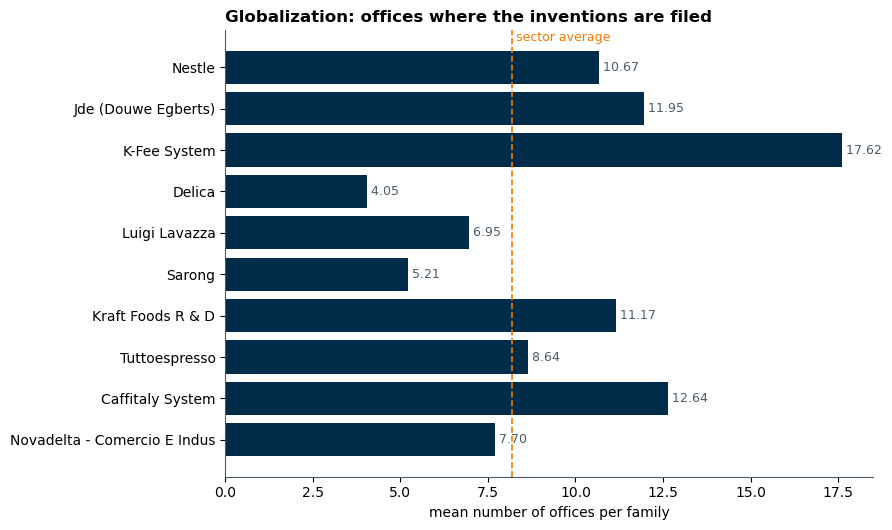

In [30]:
families["offices"] = families.docdb_family_id.map(national.groupby("docdb_family_id").appln_auth.nunique()).fillna(1)
globalization = per_firm("offices").rename("globalization")

print("Most frequent offices in the families of the sector:")
print(national.appln_auth.value_counts().head(8).to_string())
firm_bars(globalization, "Globalization: offices where the inventions are filed",
          "mean number of offices per family", ref=families.offices.mean(), ref_label="sector average")

### 7.2 Refinement: in which European states are the EP patents validated?

A granted EP patent is not yet protection anywhere: the owner must **validate** it in each state (the total of possible EPC states is 40, as per June 2026) where it wants protection (translations, fees), and then pay a **renewal** fee every year in each of them. The number of states is a strong signal of how much the owner values the patent, because each state costs money every year.

PATSTAT has this in the **legal events** (`TLS231`), not in `TLS201`. Three event codes describe the life of an EP patent in each state (data catalog, `EVENT_CODE`):

| Code | Meaning | Country in |
|---|---|---|
| `PGFP` | annual fee paid to a national office: the patent is (or was) valid there | `fee_country` |
| `VSFP` | annual fee paid to a **validation state** outside the EPC (e.g. Morocco) | `fee_country` |
| `PG25` | patent **lapsed** in a state, with the reason in `lapse_text` | `lapse_country` |

`PG25` needs care, because its reason changes everything:

- *"lapse because of **non-payment of due fees**"*: the patent was valid there, then the owner stopped paying. **Validated.**
- *"lapse because of **failure to submit a translation** of the description or to pay the fee within the prescribed time-limit"*: the owner never validated the patent there. Many offices publish this for every state the owner skipped, so a patent can have a `PG25` for 30 states. **Not validated.**

So a state counts as validated if it has a `PGFP` or `VSFP`, or a `PG25` for non-payment of fees. Before counting, a **check** on the raw data: the events by code, the reasons of the lapses, and what one patent looks like.

Source for all the codes related to patents' legal events: https://www.epo.org/en/searching-for-patents/data/coverage/weekly 

In [31]:
ep_granted = [int(i) for i in ep.loc[ep.granted == "Y", "appln_id"]]
q = (
    db.query(TLS231_INPADOC_LEGAL_EVENT.appln_id, TLS231_INPADOC_LEGAL_EVENT.event_code,
             TLS231_INPADOC_LEGAL_EVENT.fee_country, TLS231_INPADOC_LEGAL_EVENT.lapse_country,
             TLS231_INPADOC_LEGAL_EVENT.lapse_text)
    .filter(TLS231_INPADOC_LEGAL_EVENT.appln_id.in_(ep_granted))
    .filter(TLS231_INPADOC_LEGAL_EVENT.event_code.in_(["PGFP", "VSFP", "PG25"]))
)
events_val = patstat.df(q)
events_val["lapse_text"] = events_val.lapse_text.fillna("").str.upper()
print("Events by code:", events_val.event_code.value_counts().to_dict())
print("\nReasons of the PG25 lapses:")
print(events_val[events_val.event_code == "PG25"].lapse_text.str[:70].value_counts().head(5).to_string())

# validated = fee paid (PGFP, VSFP), or lapsed for non-payment after being valid (PG25 + NON-PAYMENT)
lapsed_after_valid = (events_val.event_code == "PG25") & events_val.lapse_text.str.contains("NON-PAYMENT")
val = events_val[events_val.event_code.isin(["PGFP", "VSFP"]) | lapsed_after_valid].copy()
val["country"] = np.where(val.event_code == "PG25", val.lapse_country, val.fee_country)
val["country"] = val.country.fillna("").str.strip()
val = val[(val.country != "") & (val.country != "EP")].drop_duplicates(["appln_id", "country"])
example = val.appln_id.value_counts().index[0]
print(f"\nOne granted EP application ({example}) and its states:")
val[val.appln_id == example][["event_code", "country"]].sort_values("country")

Events by code: {'PG25': 19240, 'PGFP': 5623}

Reasons of the PG25 lapses:
lapse_text
LAPSE BECAUSE OF FAILURE TO SUBMIT A TRANSLATION OF THE DESCRIPTION OR    14447
LAPSE BECAUSE OF NON-PAYMENT OF DUE FEES                                   4786
LAPSE BECAUSE OF THE APPLICANT RENOUNCES                                      4
THE PATENT HAS BEEN ANNULLED BY A DECISION OF A NATIONAL AUTHORITY            3

One granted EP application (415662599) and its states:


,event_code,country
3207,PGFP,AL
4572,PGFP,AT
1689,PGFP,BE
2789,PGFP,BG
5209,PGFP,CH
105,PGFP,CY
1173,PGFP,CZ
439,PGFP,DE
2252,PGFP,DK
1779,PGFP,EE


Now the two things worth looking at: **how many** states each patent is validated in, and **which** states. A typical pattern is a few "core" states for almost every patent (Germany, France, the UK) and a long tail of states chosen only for the important ones.

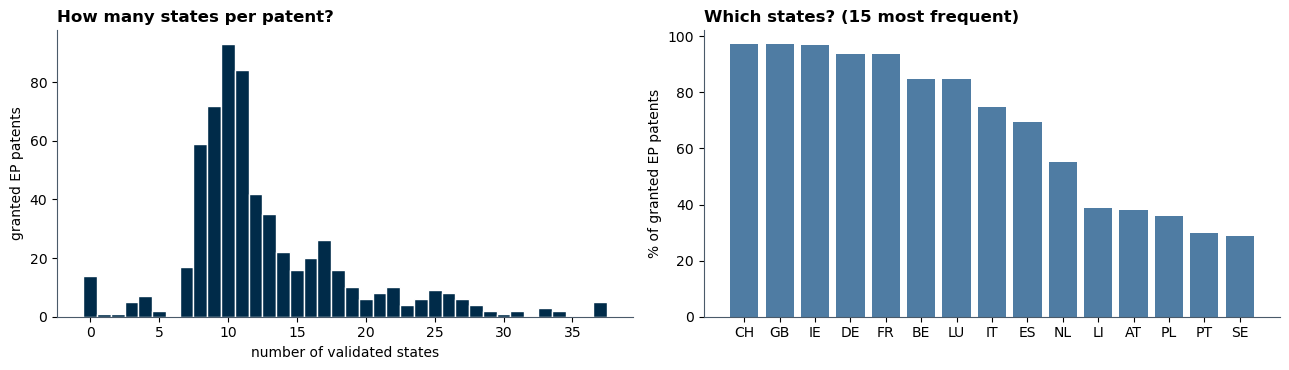

Granted EP patents with no validation event: 2%


In [32]:
states = val.groupby("appln_id").country.nunique()
n_states = pd.Series(ep_granted).map(states).fillna(0)          # granted patents with no event: 0 states
country_share = val.country.value_counts() / len(ep_granted)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(n_states, bins=range(0, int(n_states.max()) + 2), color=NAVY, edgecolor="white", align="left")
axes[0].set_xlabel("number of validated states")
axes[0].set_ylabel("granted EP patents")
axes[0].set_title("How many states per patent?")
top = country_share.head(15)
axes[1].bar(top.index, top.values * 100, color=BLUE)
axes[1].set_ylabel("% of granted EP patents")
axes[1].set_title("Which states? (15 most frequent)")
plt.tight_layout()
plt.show()
print(f"Granted EP patents with no validation event: {(n_states == 0).mean():.0%}")

The indicator for a firm: the mean number of validated states of its **granted** EP families (a family takes its best EP patent).

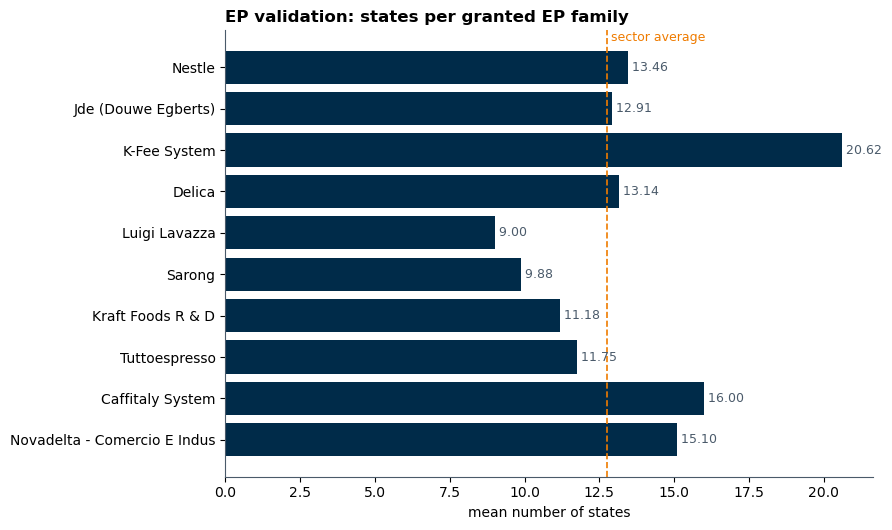

In [33]:
ep_g = ep[ep.granted == "Y"].copy()
ep_g["states"] = ep_g.appln_id.map(states).fillna(0)
families["ep_states"] = families.docdb_family_id.map(ep_g.groupby("docdb_family_id").states.max())
ep_states = per_firm("ep_states")

firm_bars(ep_states, "EP validation: states per granted EP family", "mean number of states",
          ref=families.ep_states.mean(), ref_label="sector average")

**Offices** tell where the firm *applied* (USA, China, Japan...); **validated states** tell where in Europe it *kept* the granted patent. A firm can file everywhere and then validate only in Germany: a cheaper strategy, and a weaker signal.

### 7.3 Refinement: quadrilateral families, the Clarivate measure

Counting offices treats every office the same: Brazil counts as much as the United States. Clarivate looks instead at the **four main markets**, the offices of China (CN), Europe (EP), Japan (JP) and the United States (US). A **quadrilateral family** is filed at all four: an expensive choice, made only for inventions with a global market.

$$\text{Quadrilateral share}_f=\frac{\text{families of } f \text{ filed at CN, EP, JP and US}}{\text{families of } f}$$

Every family of our sample has an EP application (that is how we selected the sector), so the question is whether the other three offices are there too.

Quadrilateral families in the sector: 47%


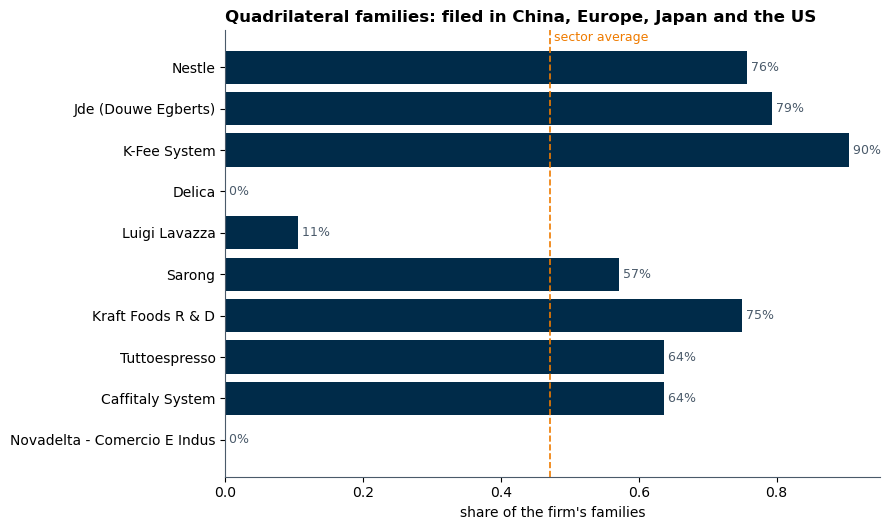

In [34]:
QUAD = {"CN", "EP", "JP", "US"}

quad = national.groupby("docdb_family_id").appln_auth.apply(lambda offices: QUAD.issubset(set(offices)))
families["quadrilateral"] = families.docdb_family_id.map(quad).fillna(False).astype(int)
quadrilateral_share = per_firm("quadrilateral").rename("quadrilateral_share")

print(f"Quadrilateral families in the sector: {families.quadrilateral.mean():.0%}")
firm_bars(quadrilateral_share, "Quadrilateral families: filed in China, Europe, Japan and the US",
          "share of the firm's families", fmt="{:.0%}", ref=families.quadrilateral.mean(), ref_label="sector average")

## 8. From four indicators to one ranking

Each firm now has four numbers. To rank the firms we need **one** number per firm, and we get there in three steps:

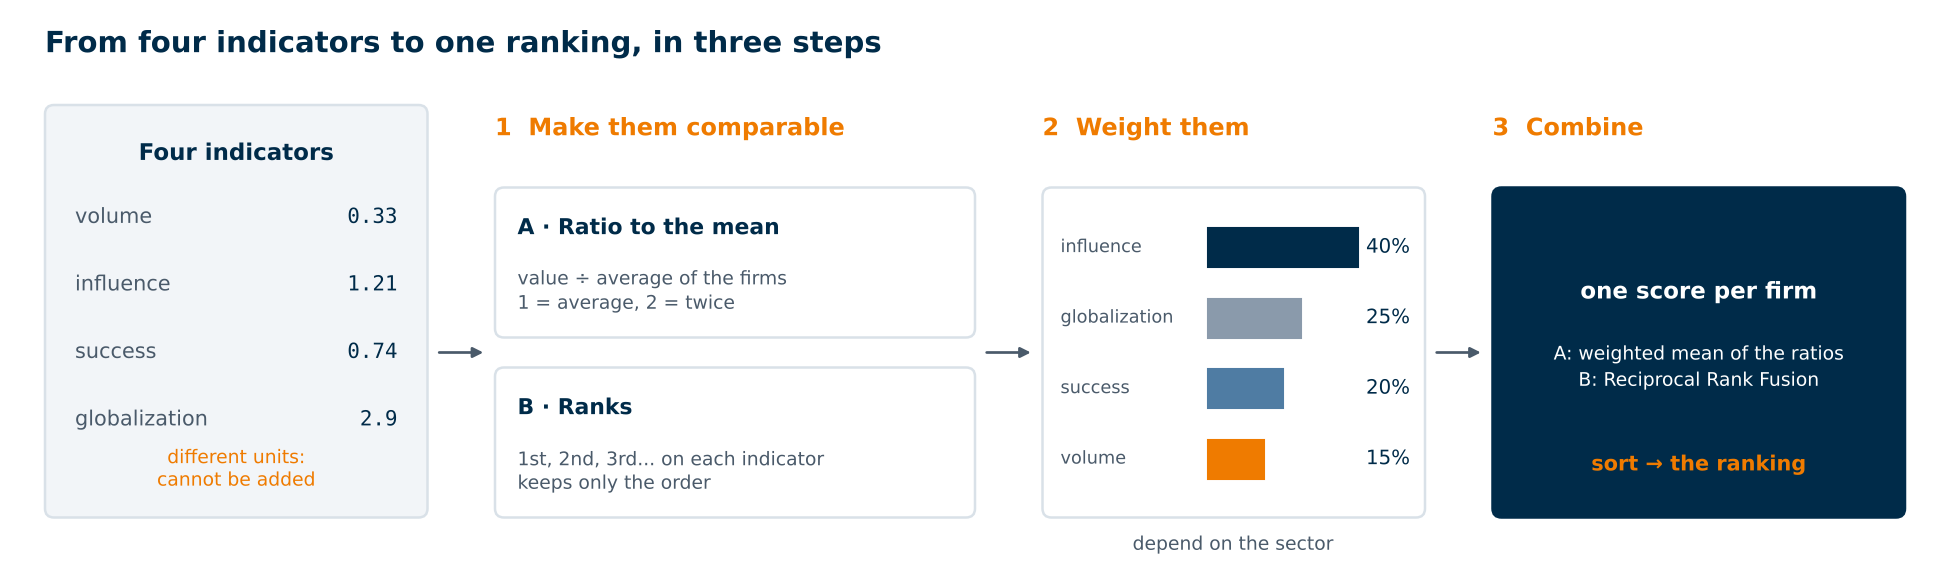

1. **make the indicators comparable**, because they are in different units;
2. **choose the weights**: how much each dimension counts for your sector;
3. **combine** them into one score, and sort.

The starting point is the indicator table: one row per firm, one column per basic indicator. The refinements go in a second table, `extras`, used in section 10.

In [35]:
INDICATORS = ["volume", "influence", "success", "globalization"]

firms = pd.concat([n_families.reindex(TOP).rename("families"), volume, influence, success, globalization], axis=1)
extras = pd.concat([volume_change, by_window, applicant_share, blocking_share, blocking_power,
                    family_success, ep_states, quadrilateral_share], axis=1)
firms.round(3)

,families,volume,influence,success,globalization
firm,,,,,
NESTLE,136,0.192,1.116,0.727,10.669
JDE (DOUWE EGBERTS),58,0.082,0.826,0.738,11.948
K-FEE SYSTEM,21,0.030,1.266,0.568,17.619
DELICA,19,0.027,0.574,0.640,4.053
LUIGI LAVAZZA,19,0.027,0.838,0.714,6.947
SARONG,14,0.020,1.393,0.562,5.214
KRAFT FOODS R & D,12,0.017,0.870,0.833,11.167
TUTTOESPRESSO,11,0.016,1.166,0.692,8.636
CAFFITALY SYSTEM,11,0.016,1.578,1.000,12.636


### 8.1 Why the numbers must be made comparable first

If we ranked the firms on **one** indicator, we would simply sort the table. The problem comes when we put four indicators together: they are in different units.

| Indicator | Unit | Typical values |
|---|---|---|
| volume | share of the sector | 0.01 – 0.3 |
| influence | ratio to the mean of the year | 0.5 – 2 |
| success | share of applications | 0.4 – 0.9 |
| globalization | number of offices | 1 – 10 |

If we simply added the raw values, the indicator with the **largest numbers** (globalization, up to 10) would decide the ranking, and volume (never above 0.3) would count almost nothing: an accident of units, not a choice of ours.

### 8.2 Step 1 · Make the indicators comparable: two solutions

| | **A · Ratio to the mean** | **B · Ranks** |
|---|---|---|
| How | divide each value by the average of the scored firms | on each indicator, sort the firms: 1st, 2nd, 3rd... |
| Reads as | "1.4 = 40% above the average firm" | "3rd of 10 on influence" |
| Keeps | the **size of the gaps** | only the **order** |

**A · Ratio to the mean.** The same idea as the normalisation of influence (5.1): there each family was compared with the average of its year, here each firm with the average firm. The map shows the ratios: blue above the average firm, red below.

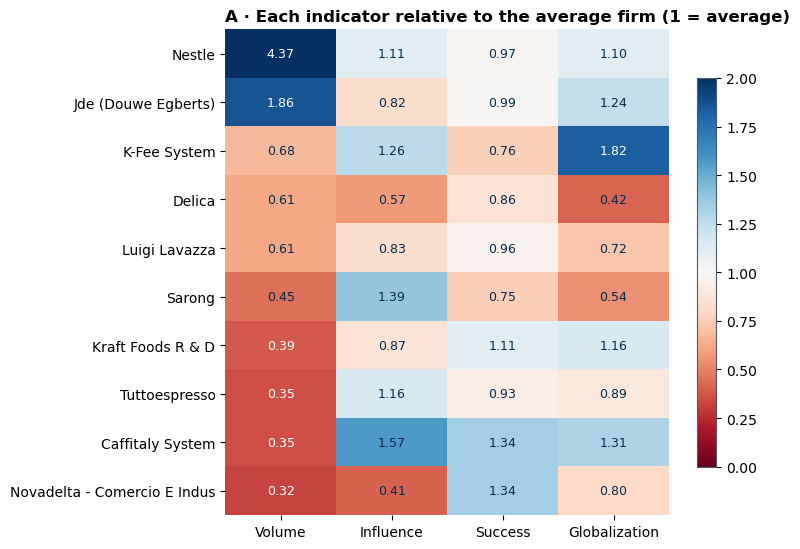

In [36]:
relative = firms[INDICATORS] / firms[INDICATORS].mean()              # A: 1 = average firm

fig, ax = plt.subplots(figsize=(8, 0.42 * len(relative) + 1.4))
im = ax.imshow(relative.values, cmap="RdBu", vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(len(INDICATORS)), [k.capitalize() for k in INDICATORS])
ax.set_yticks(range(len(relative)), [SHORT[f] for f in relative.index])
for i in range(relative.shape[0]):
    for j in range(relative.shape[1]):
        v = relative.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v - 1) > 0.6 else NAVY)
ax.spines[:].set_visible(False)
ax.set_title("A · Each indicator relative to the average firm (1 = average)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

Read the map **by rows**: a firm blue everywhere is strong on all four dimensions; a firm blue only on volume is big but not necessarily valuable. Look at the volume column: a value far above 2 means one firm is much bigger than the others.

**B · Ranks.** On each indicator we give position 1 to the best firm, 2 to the second, and so on. The best way to see ranks is a **leaderboard**: one column per indicator, the firms sorted from the 1st (top) to the last (bottom). Each firm keeps its colour, and a thin line follows it from one column to the next: a firm that stays near the top across the columns is strong everywhere; a line that zigzags is a firm strong on some dimensions and weak on others.

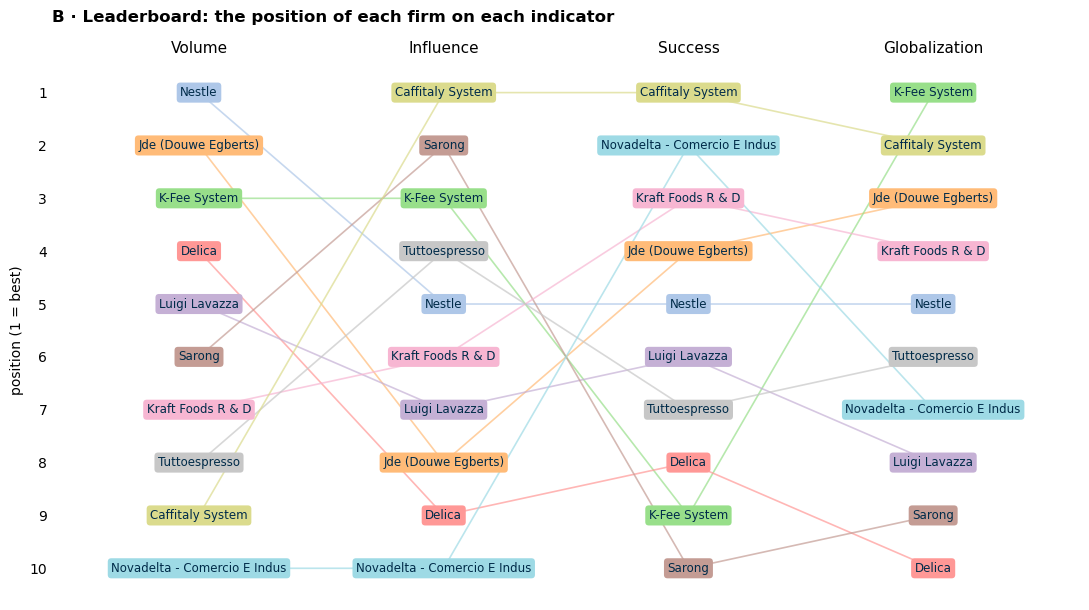

In [37]:
positions = firms[INDICATORS].rank(ascending=False, method="min")    # B: 1 = best firm on that indicator
shown = firms[INDICATORS].rank(ascending=False, method="first")       # same order, ties split only for the drawing

colour = {f: plt.cm.tab20(2 * k % 20 + 1) for k, f in enumerate(TOP)}
fig, ax = plt.subplots(figsize=(11, 0.5 * len(TOP) + 1.2))
for f in TOP:
    ax.plot(range(len(INDICATORS)), shown.loc[f, INDICATORS], color=colour[f], lw=1.2, alpha=0.7, zorder=1)
    for j, k in enumerate(INDICATORS):
        ax.text(j, shown.loc[f, k], SHORT[f], ha="center", va="center", fontsize=8.5, color=NAVY, zorder=2,
                bbox=dict(boxstyle="round,pad=0.3", fc=colour[f], ec="none"))
ax.set_xlim(-0.6, len(INDICATORS) - 0.4)
ax.set_ylim(len(TOP) + 0.6, 0.4)
ax.set_xticks(range(len(INDICATORS)), [k.capitalize() for k in INDICATORS], fontsize=11)
ax.xaxis.tick_top()
ax.set_yticks(range(1, len(TOP) + 1))
ax.set_ylabel("position (1 = best)")
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
ax.set_title("B · Leaderboard: the position of each firm on each indicator", pad=28)
plt.tight_layout()
plt.show()

### 8.3 Ratio to the mean or ranks? How to choose

The two solutions answer **different questions**. The ratio to the mean asks *how much* better a firm is; ranks ask *where* a firm stands, whatever the size of the gaps.

| Choose the **ratio to the mean** when... | Choose **ranks** when... |
|---|---|
| the size of the gaps is part of the answer: the bank wants to know if the leader is a little or a lot ahead | the question is "who is first?" (a shortlist of targets) |
| the indicators are not too skewed: no firm far above 2-3 times the average | one indicator is very skewed (a giant firm): with the mean it would decide the ranking alone |
| each firm has enough patents for its values to be reliable: small differences are real | the values are noisy: you trust the order more than the exact numbers |

**Watch out with the mean**: a skewed indicator can be tamed by transforming it before the ratio (e.g. the logarithm of volume).

**Watch out with ranks**: tiny differences become full positions (a success rate of 0.71 against 0.73 is one position, like 0.50 against 0.90).




### 8.4 Step 2 · Choose the weights

The weights $w_k$ say how much each dimension counts; they sum to 1. Equal weights ($w_k = 1/4$) are also a choice: they say that size counts as much as impact.

**There is no universal set of weights: each sector needs its own**, because sectors use patents differently:

| Sector | How patents are used | What should weigh more |
|---|---|---|
| Pharmaceuticals, biotech | few patents, each protecting a whole product; long examinations; protection in many countries | **success**, **globalization**, influence; volume much less |
| Electronics, telecom | thousands of patents per firm, thickets, standards, cross-licensing | **volume** and **globalization**; citations are noisy |
| Consumer goods, e.g. coffee capsules | designs easy to copy, fast entry of competitors, litigation | **influence** and blocking patents (5.4), success |
| Software, AI | short life of the technology, many applications still pending | short citation windows (5.2), volume over time (4.2) |

The weights below are an **example for coffee capsules**, not the right answer. Yours must come from your sector and from the question of your bank, and you must say where they come from: your reasoning, the literature, experts you asked.

In [39]:
WEIGHTS = {"influence": 0.40, "globalization": 0.25, "success": 0.20, "volume": 0.15}
print("Sum of the weights:", round(sum(WEIGHTS.values()), 3))

Sum of the weights: 1.0


### 8.5 Step 3 · Combine

Now the comparable indicators become **one score per firm**. Each of the two solutions has its own way to combine.

#### A · Weighted mean of the ratios

$$\text{Score}_f=100\cdot\sum_k w_k\cdot\frac{x_{f,k}}{\bar x_k}\qquad(100 = \text{average firm})$$

It is **compensatory**: a lot of one indicator makes up for little of another. With our weights, a firm 4.4 times bigger than the average gets 100 × 0.15 × 4.4 = 66 points from volume alone, two thirds of the score of an average firm.

#### B · Reciprocal Rank Fusion (RRF) of the ranks

Combining several rankings into one is a classic problem of **search engines**: several algorithms each rank the web pages, and one list must be shown. **Reciprocal Rank Fusion** (Cormack et al. 2009: https://dl.acm.org/doi/10.1145/1571941.1572114) is the standard solution, and it works the same for our firms: each indicator is one ranking. Every position is turned into points with $1/(c+\text{position})$, then the points are added with the weights:

$$\text{RRF}_f=100\cdot\sum_k w_k\cdot\frac{c+1}{c+\text{position}_{f,k}}\qquad(100 = \text{first on every indicator})$$

- being **at the top** of an indicator gives many points; moving up in the middle of the list gives few;
- $c$ sets how much the top counts. The original paper used $c = 60$ for lists of hundreds of web pages; with 10 firms we use $c$ = number of firms. The table shows how many points each position is worth (1st = 100):

In [40]:
RRF_C = len(TOP)                         # the constant c of RRF: the number of firms

pos = np.arange(1, len(TOP) + 1)
pd.DataFrame({"points": (100 * (RRF_C + 1) / (RRF_C + pos)).round(0).astype(int)},
             index=pd.Index(pos, name="position")).T

position,1,2,3,4,5,6,7,8,9,10
points,100,92,85,79,73,69,65,61,58,55


**A worked example: the giant and the specialist.** Two firms, equal weights. Firm X is the largest of the sector but average on the rest; firm Y is small but excellent.

| | volume | influence | success | globalization | A · Mean | B · RRF ($c$=10) |
|---|---|---|---|---|---|---|
| X: position (ratio) | 1st (4.4) | 5th (1.1) | 5th (1.0) | 5th (0.9) | **185** | 80 |
| Y: position (ratio) | 8th (0.6) | 1st (1.5) | 1st (1.3) | 2nd (1.2) | 115 | **88** |

The mean puts X first: its size (4.4 times the average) compensates for everything else. RRF puts Y first: it is at the top of three indicators out of four. Neither is wrong: they answer different questions (8.3).

One function computes both, so that sections 9 and 10 can reuse it:

In [41]:
def combine(table, weights, method):
    """One score per firm, higher = better. 'mean': 100 = average firm. 'rrf': 100 = first on every indicator."""
    w = pd.Series(weights, dtype=float)
    w = w / w.sum()
    t = table[w.index]
    if method == "mean":
        return 100 * (t / t.mean() * w).sum(axis=1)
    if method == "rrf":
        pos = t.rank(ascending=False, method="min")           # 1 = best on each indicator
        return 100 * (w * (RRF_C + 1) / (RRF_C + pos)).sum(axis=1)
    raise ValueError("method must be 'mean' or 'rrf'")


def final_rank(scores, method=None):
    """From scores to the ranking: 1 = best firm."""
    return scores.rank(ascending=False, method="min").astype(int)


both = pd.DataFrame({"A · mean": combine(firms, WEIGHTS, "mean"), "B · RRF": combine(firms, WEIGHTS, "rrf")})
both["rank A"] = final_rank(both["A · mean"])
both["rank B"] = final_rank(both["B · RRF"])
positions.astype(int).add_prefix("pos. ").join(both.round(1)).sort_values("rank B").rename(index=SHORT)

,pos. volume,pos. influence,pos. success,pos. globalization,A · mean,B · RRF,rank A,rank B
firm,,,,,,,,
Caffitaly System,8,1,1,2,127.6,92.1,2,1
K-Fee System,3,3,9,1,121.4,83.1,3,2
Nestle,1,5,5,5,157.1,77.3,1,3
Jde (Douwe Egberts),2,8,4,3,111.5,75.1,4,4
Kraft Foods R & D,7,6,3,4,91.6,73.8,6,5
Sarong,6,2,10,9,90.8,72.5,7,6
Tuttoespresso,8,4,7,6,92.6,70.7,5,7
Luigi Lavazza,4,7,6,8,79.6,66.7,8,8
Novadelta - Comercio E Indus,10,10,1,7,68.1,66.4,9,9


**How to read the table.** The first four columns are the positions on each indicator; then the two scores and their rankings.

- A firm with the **same rank in A and B** is placed the same way whatever the method: a solid result.
- A firm **much higher in A than in B** is far ahead on one indicator (often volume): the mean rewards the size of its lead, RRF does not.

With the mean we can also show **what makes** each score: each indicator contributes $100\cdot w_k\cdot x_{f,k}/\bar x_k$.

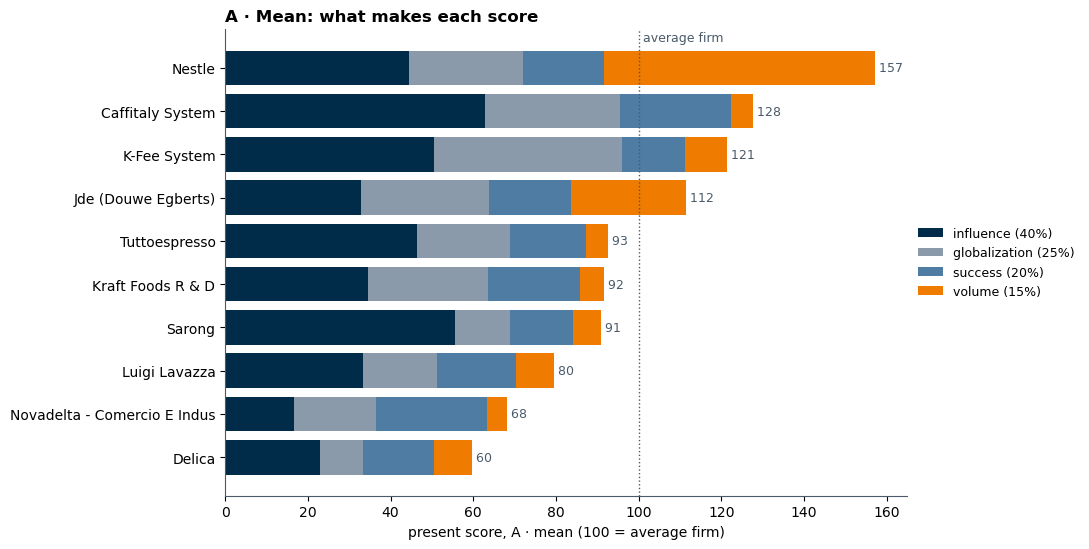

In [42]:
w = pd.Series(WEIGHTS)
contrib = 100 * relative[w.index] * w
order = combine(firms, WEIGHTS, "mean").sort_values().index

fig, ax = plt.subplots(figsize=(11, 0.42 * len(order) + 1.4))
left = np.zeros(len(order))
colours = {"influence": NAVY, "globalization": MID, "success": BLUE, "volume": ORANGE}
for k in w.index:
    vals = contrib.loc[order, k].values
    ax.barh([SHORT[f] for f in order], vals, left=left, color=colours[k], label=f"{k} ({w[k]:.0%})")
    left += vals
for y, x in enumerate(left):
    ax.text(x, y, f" {x:.0f}", va="center", fontsize=9, color=GREY)
ax.axvline(100, color=GREY, ls=":", lw=1)
ax.text(100, len(order) - 0.45, " average firm", color=GREY, fontsize=9, va="bottom")
ax.set_xlabel("present score, A · mean (100 = average firm)")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
ax.set_title("A · Mean: what makes each score")
plt.tight_layout()
plt.show()

#### The final ranking

Choose the method with `METHOD`, and write in the deck **why**, using the guide of 8.3.

In [57]:
METHOD = "rrf"              # "mean" (A) or "rrf" (B)

firms["score"] = combine(firms, WEIGHTS, METHOD)
firms["rank"] = final_rank(firms.score)
firms.sort_values("rank")[["families", "score", "rank"]].round(1).rename(index=SHORT)

,families,score,rank
firm,,,
Caffitaly System,11,92.1,1
K-Fee System,21,83.1,2
Nestle,136,77.3,3
Jde (Douwe Egberts),58,75.1,4
Kraft Foods R & D,12,73.8,5
Sarong,14,72.5,6
Tuttoespresso,11,70.7,7
Luigi Lavazza,19,66.7,8
Novadelta - Comercio E Indus,10,66.4,9


## 9. Is the ranking robust?

The method and the weights are assumptions, and a ranking that changes completely with small changes of the assumptions tells us little. Section 8.5 already compared the two **methods** with the same weights. Here we keep the chosen method and change the **weights**: equal, size first, impact first (ours), and leaving one indicator out at a time.

In [58]:
SCHEMES = {
    "equal": {k: 1 for k in INDICATORS},
    "impact first (ours)": WEIGHTS,
    "size first": {"influence": 0.15, "globalization": 0.25, "success": 0.20, "volume": 0.40},
}
for k in INDICATORS:
    SCHEMES[f"without {k}"] = {j: 1 for j in INDICATORS if j != k}

by_weights = pd.DataFrame({name: final_rank(combine(firms, w, METHOD), METHOD) for name, w in SCHEMES.items()})
by_weights.rename(index=SHORT).sort_values("impact first (ours)")

,equal,impact first (ours),size first,without volume,without influence,without success,without globalization
firm,,,,,,,
Caffitaly System,1,1,4,1,2,2,1
K-Fee System,2,2,2,2,4,1,4
Nestle,3,3,1,5,3,3,2
Jde (Douwe Egberts),4,4,3,4,1,4,3
Kraft Foods R & D,5,5,5,3,5,6,5
Sarong,7,6,7,8,10,5,6
Tuttoespresso,9,7,9,7,9,7,9
Luigi Lavazza,8,8,6,9,7,8,7
Novadelta - Comercio E Indus,6,9,8,6,6,10,8


Each column is one ranking (1 = best). How close is each one to ours (Spearman: 1 = same order)?

In [59]:
by_weights.corr(method="spearman")["impact first (ours)"].drop("impact first (ours)").round(2).sort_values().to_frame(
    "correlation with our ranking")

,correlation with our ranking
without influence,0.71
size first,0.85
without volume,0.87
equal,0.92
without globalization,0.93
without success,0.96


How to read it:

- firms that stay in the **top positions in every ranking**, here and in 8.5, are a safe recommendation;
- a firm that jumps when one indicator is dropped owes its position to that indicator: say so in the deck;
- correlations above about 0.8 mean the ranking does not depend much on the assumptions. If they are low, your assumptions *are* your result, and you must defend them carefully.

## 10. Using a refinement in the score

A refinement can **replace** a basic indicator (a better measure of the same thing) or be **added** as a fifth one. Two examples for coffee capsules:

- replace globalization (offices) with the **quadrilateral share** (7.3), the Clarivate measure, if your bank cares about the main world markets;
- add **blocking patents** (5.4), because in a sector of copies and litigations blocking power is value.

In [60]:
table = pd.concat([firms[INDICATORS], extras], axis=1)

variants = {
    "basic (ours)": WEIGHTS,
    "quadrilateral instead of offices": {"influence": 0.40, "quadrilateral_share": 0.25, "success": 0.20,
                                         "volume": 0.15},
    "plus blocking patents": {"influence": 0.30, "blocking_share": 0.15, "globalization": 0.25, "success": 0.15,
                              "volume": 0.15},
}
compare = pd.DataFrame({name: final_rank(combine(table, w, METHOD), METHOD) for name, w in variants.items()})
compare.rename(index=SHORT).sort_values("basic (ours)")

,basic (ours),quadrilateral instead of offices,plus blocking patents
firm,,,
Caffitaly System,1,1,1
K-Fee System,2,2,2
Nestle,3,3,3
Jde (Douwe Egberts),4,4,4
Kraft Foods R & D,5,6,5
Sarong,6,5,7
Tuttoespresso,7,7,6
Luigi Lavazza,8,8,8
Novadelta - Comercio E Indus,9,9,9


If a refinement moves a firm by several positions, it tells you something the basic indicator missed: explain it in the deck.